Import the libraries required for data analysis

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import re

Load the uploaded CSV dataset

In [83]:
df = pd.read_csv('/content/archive (1).zip')

In [84]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Display the first five records

In [85]:
df.head()

,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),listed_in(type)
0,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,Buffet
1,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,Buffet
2,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,Buffet
3,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,Buffet
4,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,Buffet


Display the number of rows and columns

In [86]:
print("Dataset shape:", df.shape)

Dataset shape: (56252, 13)


Display column names

In [87]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'listed_in(type)']


Display data types and non-null values

In [88]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56252 entries, 0 to 56251
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   address                      56235 non-null  object
 1   name                         56236 non-null  object
 2   online_order                 56233 non-null  object
 3   book_table                   56194 non-null  object
 4   rate                         48414 non-null  object
 5   votes                        56174 non-null  object
 6   phone                        54956 non-null  object
 7   location                     56126 non-null  object
 8   rest_type                    55914 non-null  object
 9   dish_liked                   28027 non-null  object
 10  cuisines                     56049 non-null  object
 11  approx_cost(for two people)  55731 non-null  object
 12  listed_in(type)              51642 non-null  object
dtypes: object

Count missing values in each column

In [89]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
address                           17
name                              16
online_order                      19
book_table                        58
rate                            7838
votes                             78
phone                           1296
location                         126
rest_type                        338
dish_liked                     28225
cuisines                         203
approx_cost(for two people)      521
listed_in(type)                 4610
dtype: int64


Count duplicate rows

In [90]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 15703


## Data cleaning

 Remove duplicate rows

In [91]:
df = df.drop_duplicates().copy()

Clean text columns and standardize missing values

In [92]:
text_cols = df.select_dtypes(include='object').columns

for col in text_cols:
    df[col] = df[col].astype('string').str.strip()
    df[col] = df[col].replace(
        ['', 'nan', 'None', 'null', 'NaN'],
        pd.NA
    )

Convert ratings to numeric values
Example: "4.1/5" becomes 4.1

In [93]:
df['rate'] = pd.to_numeric(
    df['rate'].astype('string')
      .str.extract(r'(\d+(?:\.\d+)?)')[0],
    errors='coerce'
)

Convert approximate cost into numeric values,
 Remove commas and other non-numeric characters

In [94]:
cost_col = 'approx cost(for two people)'

df[cost_col] = pd.to_numeric(
    df[cost_col].astype('string')
      .str.replace(',', '', regex=False)
      .str.replace(r'[^0-9.]', '', regex=True),
    errors='coerce'
)

Remove rows missing the fields needed for analysis

In [95]:
df = df.dropna(
    subset=['rate', 'cuisines', 'location', cost_col]
).copy()

# Step 6: Keep valid restaurant ratings
df = df[df['rate'].between(0, 5)].copy()

Display cleaned data

In [96]:
print("Cleaned dataset shape:", df.shape)
print(df[['rate', 'cuisines', 'location', cost_col]].head())

Cleaned dataset shape: (31129, 13)
   rate                        cuisines      location  \
0   4.1  North Indian, Mughlai, Chinese  Banashankari   
1   4.1     Chinese, North Indian, Thai  Banashankari   
2   3.8          Cafe, Mexican, Italian  Banashankari   
3   3.7      South Indian, North Indian  Banashankari   
4   3.8        North Indian, Rajasthani  Basavanagudi   

   approx_cost(for two people)  
0                        800.0  
1                        800.0  
2                        800.0  
3                        300.0  
4                        600.0  


Cuisine vs rating analysis

Split multiple cuisines into individual cuisine names

In [97]:
cuisine_data = (
    df.assign(cuisine=df['cuisines'].str.split(','))
      .explode('cuisine')
)

Removing extra spaces from cuisine names

In [98]:
cuisine_data['cuisine'] = cuisine_data['cuisine'].str.strip()

Calculate average rating and restaurant count per cuisine

In [99]:
cuisine_summary = (
    cuisine_data.groupby('cuisine')
    .agg(
        average_rating=('rate', 'mean'),
        restaurant_count=('rate', 'size')
    )
    .query('restaurant_count >= 10')
    .sort_values('average_rating', ascending=False)
)

/tmp/ipykernel_868/3595836538.py:7: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  .query('restaurant_count >= 10')


Plot the top 10 cuisines by average rating

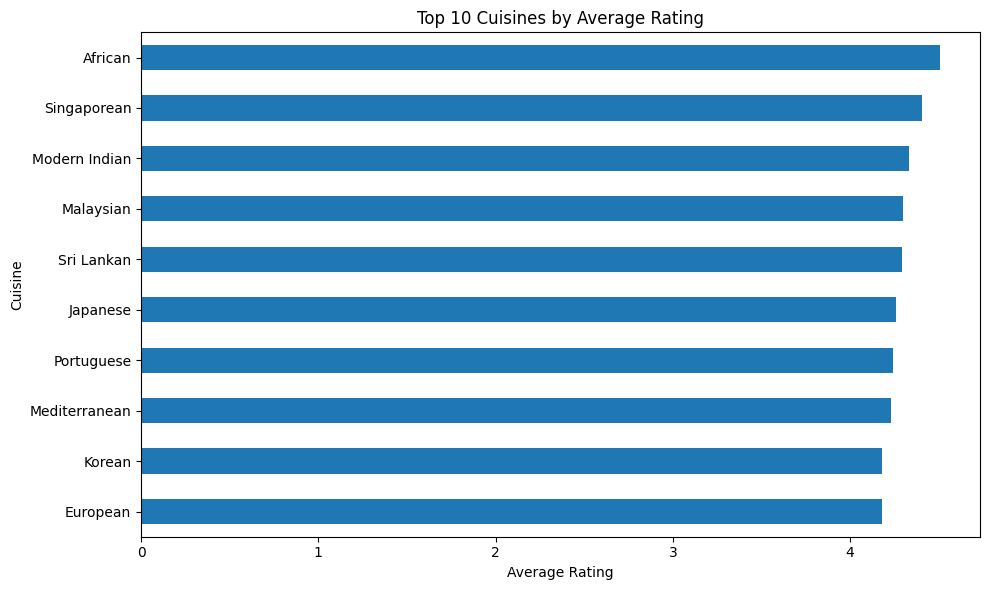

In [100]:
top_cuisines = cuisine_summary.head(10).sort_values('average_rating')

plt.figure(figsize=(10, 6))
top_cuisines['average_rating'].plot(kind='barh')
plt.title('Top 10 Cuisines by Average Rating')
plt.xlabel('Average Rating')
plt.ylabel('Cuisine')
plt.tight_layout()
plt.show()

Location hotspots analysis

Count restaurants and calculate average rating by location

In [101]:
location_summary = (
    df.groupby('location')
    .agg(
        restaurant_count=('rate', 'size'),
        average_rating=('rate', 'mean')
    )
    .sort_values('restaurant_count', ascending=False)
)


Select the 10 locations with the most restaurants

In [102]:
top_locations = location_summary.head(10)

 Plot restaurant counts by location

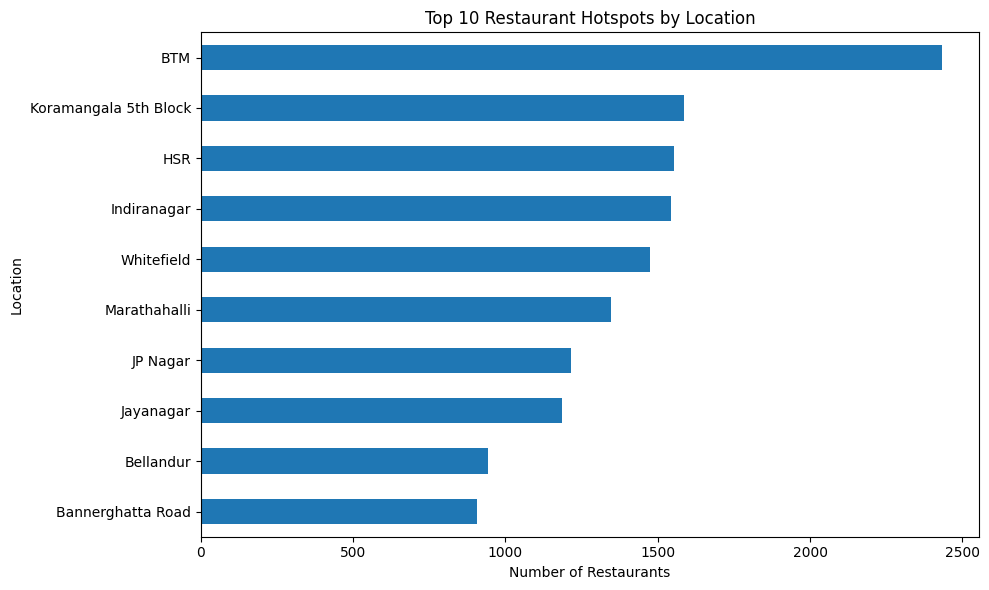

In [103]:
plt.figure(figsize=(10, 6))
top_locations['restaurant_count'].sort_values().plot(kind='barh')
plt.title('Top 10 Restaurant Hotspots by Location')
plt.xlabel('Number of Restaurants')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

Display location-wise counts and ratings

In [104]:
display(top_locations.round(2))

,restaurant_count,average_rating
location,,
BTM,2434,3.61
Koramangala 5th Block,1587,4.04
HSR,1553,3.69
Indiranagar,1544,3.83
Whitefield,1475,3.6
Marathahalli,1346,3.53
JP Nagar,1216,3.72
Jayanagar,1185,3.81
Bellandur,942,3.53


Price vs rating analysis

Define the cost column

In [105]:
cost_col = 'approx cost(for two people)'

 Plot restaurant cost against rating

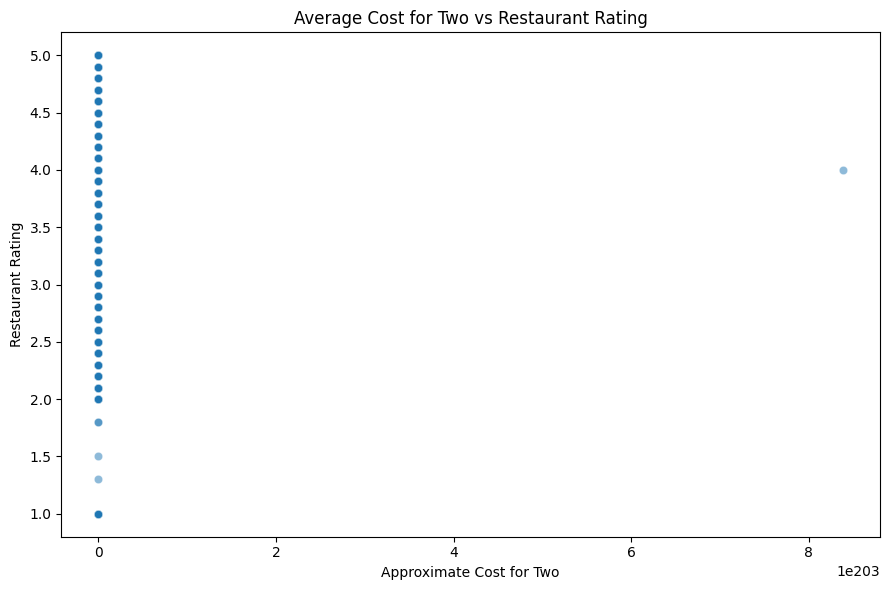

In [106]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x=cost_col,
    y='rate',
    alpha=0.5
)

plt.title('Average Cost for Two vs Restaurant Rating')
plt.xlabel('Approximate Cost for Two')
plt.ylabel('Restaurant Rating')
plt.tight_layout()
plt.show()

Calculate the correlation between cost and rating

In [107]:
correlation = df[[cost_col, 'rate']].corr().iloc[0, 1]

print("Cost-rating correlation:", round(correlation, 3))

Cost-rating correlation: 0.0


Heatmap

Select numerical columns relevant to this task

In [108]:
numeric_cols = ['rate', cost_col]

Calculate correlations between numerical variables

In [109]:
correlation_matrix = df[numeric_cols].corr()

Display the correlation heatmap

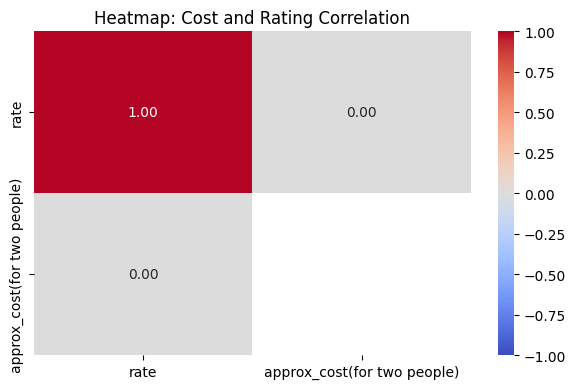

In [110]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Heatmap: Cost and Rating Correlation')
plt.tight_layout()
plt.show()

WordCloud

Combine all cuisine names into a single text string

In [111]:
cuisine_text = ' '.join(
    df['cuisines'].dropna().astype(str)
)

Generate a WordCloud from cuisine names

In [112]:
wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color='white',
    collocations=False
).generate(cuisine_text)

Display the WordCloud

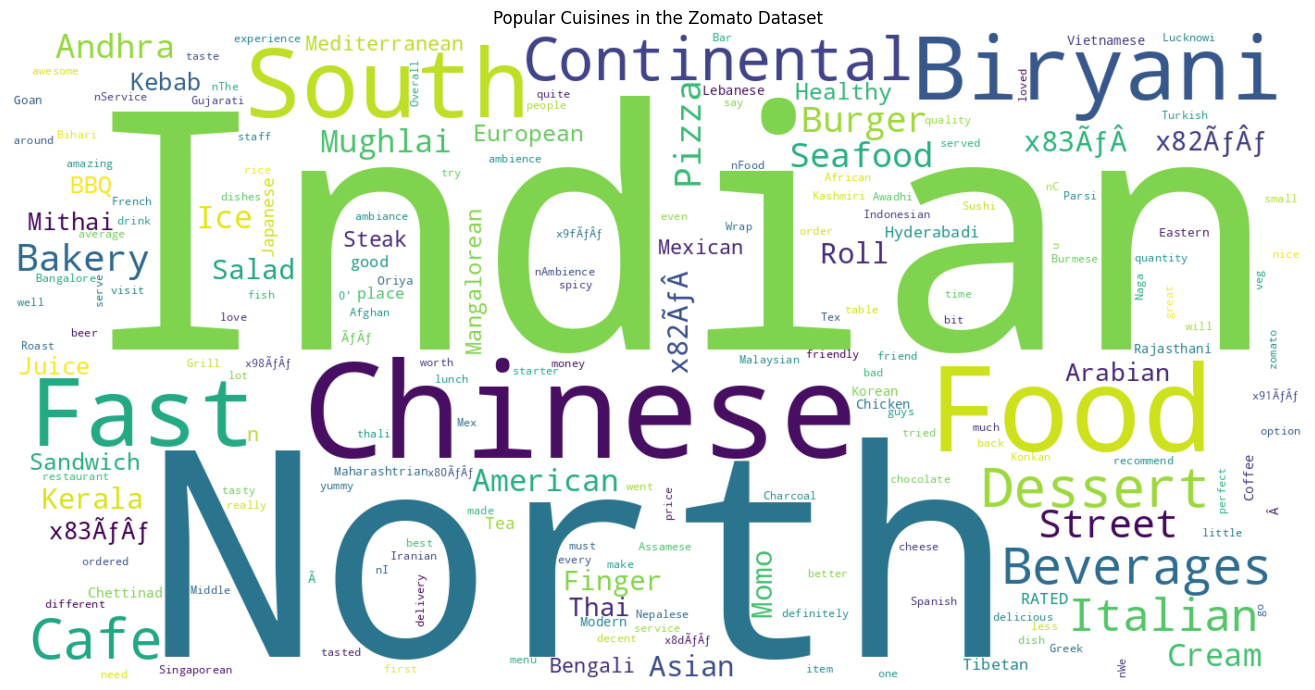

In [113]:
plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Popular Cuisines in the Zomato Dataset')
plt.tight_layout()
plt.show()

5 Recommendations for Alfido Tech

1. Restaurant Partnership Programs

Alfido Tech can partner with highly rated restaurants in popular locations to promote their services and improve restaurant visibility on the platform.

2. Cuisine-Based Marketing Campaigns

Alfido Tech can create marketing campaigns featuring popular cuisines to attract food lovers and help users discover restaurants based on their food preferences.

3. Rating-Based Restaurant Recommendations

The platform can recommend restaurants based on customer ratings and cuisine preferences, helping users make better dining decisions.

4. Budget-Friendly Restaurant Discovery

Alfido Tech can introduce budget-based restaurant recommendations by categorizing restaurants according to their average cost, helping users find suitable dining options within their budgets.

5. Food Blogs and Digital Content Creation

Alfido Tech can publish food blogs, restaurant reviews, and popular cuisine guides to increase user engagement, improve online visibility, and attract more visitors to the platform.